In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

!pip install --no-deps d2l
import torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.7/111.7 kB 1.8 MB/s eta 0:00:00


## 2.1 数据操作
- 核心数据类型：张量`tensor`
  - 一个由数值组成的n维数组；
  - 一维张量又称向量`vector`，二维张量又称为矩阵`matrix`

### 2.1.1 基础

In [2]:
## 基础属性及创建方式

x = torch.arange(12)
print(f"x形如\n{x}\n")

## 查看形状
print(f"x的形状为\n{x.shape}\n")

## 查看总长度
print(f"x的元素总数为\n{x.numel()}")

x形如
tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

x的形状为
torch.Size([12])

x的元素总数为
12


In [3]:
## 改变张量形状
X = x.reshape(3, 4)

### 维度的自动计算机制 
X_1 = x.reshape(-1, 4) 
X_2 = x.reshape(3, -1)
X, X_1, X_2
### 结果一致

(tensor([[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]]),
 tensor([[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]]),
 tensor([[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]]))

In [4]:
## 使用其他函数初始化张量
print(f"初始化零值张量：\n{torch.zeros((3, 4, 5))}\n")

print(f"初始化值为1的张量：\n{torch.ones((3, 4, 5))}\n")

print(f"使用标准正态分布进行初始化的张量：\n{torch.randn((3, 4))}\n")

print(f"自定义数值创建张量：\n{torch.tensor([[2, 1, 3, 4], [1, 2, 3, 4], [1, 3, 4, 2]])}")

初始化零值张量：
tensor([[[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]])

初始化值为1的张量：
tensor([[[1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.]],

        [[1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.]],

        [[1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1.]]])

使用标准正态分布进行初始化的张量：
tensor([[ 0.8166,  0.5759,  0.0536,  0.9142],
        [ 0.5427,  1.4045, -0.7874, -0.0184],
        [-2.2416, -0.3823,  0.8550, -1.0424]])

自定义数值创建张量：
tensor([[2, 1, 3, 4],
        [1, 2, 3, 4],
        [

## 2.1.2 运算符
两个形状相同的张量**按元素**进行运算，包括：
- 加法 `+`
- 减法 `-`
- 乘法 `*`
- 除法 `/`
- 幂运算 `**`
- 自然常数幂 $ e ^ x $ 

In [5]:
x = torch.tensor([1.2, 3, 6, 8])
y = torch.tensor([2, 1, 3, 4])
x + y, x - y, x * y, x / y, x ** y, torch.exp(x)

(tensor([ 3.2000,  4.0000,  9.0000, 12.0000]),
 tensor([-0.8000,  2.0000,  3.0000,  4.0000]),
 tensor([ 2.4000,  3.0000, 18.0000, 32.0000]),
 tensor([0.6000, 3.0000, 2.0000, 2.0000]),
 tensor([1.4400e+00, 3.0000e+00, 2.1600e+02, 4.0960e+03]),
 tensor([   3.3201,   20.0855,  403.4288, 2980.9580]))

#### 其他常见的运算：
- 点积（dot） $\cdot$
- 矩阵乘法
- 逻辑运算
- 求和、平均

In [6]:
##
### 点积


### 2.3.x 矩阵范数 `norm`
#### a) 含义和作用：
 - 使用一个标量数值表征一个矩阵的大小/长度
#### b) 性质：
 - 非负性：
 - 齐次性：
 - 三角不等式：
#### 常见的范数:
 - $L_1$ 范数：$\| x \| _1 = \sum_{i=1}^{n}|x_i| $  `近似于曼哈顿距离` 
 - $L_2$ 范数：$\| x \| _2 = \sqrt{\sum_{i=1}^{n}x_i^2} $ `近似于欧式距离`
 - $L_p$ 范数：$\| x \| _p = ({\sum_{i=1}^{n}|x_i|^p})^{1/p} $ `一般情况，L1、L2范数是其特殊形式`
 - $弗罗贝尼乌斯$ 范数：$\| x \| _f = \sqrt{{\sum_{i=1}^{m}}{\sum_{j=1}^{n}}|x_{ij}^2|} $ `矩阵语境下的L2范数：对每个矩阵的元素加权计算平方和后开方，以下简称弗式范数`

In [7]:
u = torch.tensor([3.0, 4.0, 7.0 ,1.0]) 

## 常见范数的实现
### L1范数
normL1 = torch.abs(u).sum()
print(f"张量u的L1范数为：{normL1}")

### L2范数
normL2 = (u ** 2).sum().sqrt() 
print(f"张量u的L2范数为：{normL2}")

#### 等价操作
print(f"张量u的L2范数为：{torch.norm(u)}")

### 弗式范数
matrix = torch.arange(12, dtype=torch.float).reshape(3, 4)
matrix[0, 0] = 3

print(f"矩阵matrix的弗式范数为：{torch.norm(matrix)}")
print(f"矩阵matrix的弗式范数为：{(matrix ** 2).sum().sqrt()}")

张量u的L1范数为：15.0
张量u的L2范数为：8.66025447845459
张量u的L2范数为：8.66025447845459
矩阵matrix的弗式范数为：22.69361114501953
矩阵matrix的弗式范数为：22.69361114501953


## 2.4 微积分基础  
### 2.4.1 导数与微分
- 导数的定义：设函数 $f(x)$ :&#8477; $\rightarrow$ &#8477;，输入和输出均为标量，其导数的极限形式为：
$$
f'(x) = \lim_{h \rightarrow 0} \frac{f(x+h) - f(x)}{h}
$$

- 可微的定义：若 $f(x)$ 在 $x=a$ 处的导数 $f'(a)$ 存在，则称其在 $a$ 处可微` differentiable `
- 导数的意义：导数 $f'(x)$ 可被解释为原函数 $f(x)$ 相对于 $x$ 的瞬时变化率，其变化率相对于微小变化量 $h$


$$
\begin{align}
(a + b)^2 &= a^2 + 2ab + b^2 \\
          &= a^2 + b^2 + 2ab
\end{align}
$$


In [8]:
## 导入所需库
%matplotlib inline
import numpy as np
from matplotlib_inline import backend_inline
from d2l import torch as d2l

In [9]:
## 进行简单的导数运算
### 定义原函数f(x)
def f(x):
    return 3 * x ** 2 - 4 * x
### 定义导函数的极限形式
def num_lim(f, x, h):
    return (f(x + h) - f(x)) / h

### 使用实例测试
h_l = [0.1, 0.05, 0.01, 0.001, 0.0001, 1e-5, 1e-6]

for h in h_l:
    print(f"h={h:.6f}时，极限为：{num_lim(f, 1, h):.10f}")

h=0.100000时，极限为：2.3000000000
h=0.050000时，极限为：2.1500000000
h=0.010000时，极限为：2.0300000000
h=0.001000时，极限为：2.0030000000
h=0.000100时，极限为：2.0003000000
h=0.000010时，极限为：2.0000300000
h=0.000001时，极限为：2.0000030001


- 常见的导数表示形式:

$$
f'(x) = y' = \frac{dy}{dx} = \frac{df}{dx} = {\frac{d}{dx}f(x)} = Df(x) = D_xf(x).     其中 \frac{d}{dx} 与 D 为微分符号
$$

- 常见的导数结果：
  - $ DC = 0 $，其中 $C$ 为常数；
  - $ Dx^n = nx^{n-1}, n \in R $；
  - $ De^x = e^x $；
  - $ Dln(x) = \frac{1}{x} $；

- 常见的导数运算法则：
  - 常数乘法法则：
$$
\frac{d}{dx}[Cf(x)] = C\frac{d}{dx}f(x)
$$
  - 加法法则：
$$
\frac{d}{dx}[f(x) + g(x)] = \frac{d}{dx}f(x) + \frac{d}{dx}g(x)
$$
  - 导数乘法法则：
$$
\frac{d}{dx}[f(x)g(x)] = f(x)\frac{d}{dx}g(x) + g(x)\frac{d}{dx}f(x)
$$
  - 除法法则：
$$
\frac{d}{dx}[\frac{f(x)}{g(x)}] = \frac{g(x)\frac{d}{dx}[f(x)] - f(x)\frac{d}{dx}[g(x)]}{[g(x)]^2}
$$

In [10]:
## 对导数的数学和物理意义进行可视化

### 定义矢量图的显示函数
def use_svg_display(): #@save in d2l
    backend_inline.set_matplotlib_formats('svg')

### 定义设置图表大小的函数
def set_figsize(figsize=(3.5, 2.5)): #@save in d2l
    use_svg_display()
    d2l.plt.rcParams['figure.figsize'] = figsize    

接下来需要对轴属性进行定义与设置：
- 轴属性：
  - `ax/axes`：表征整个绘图区；
  - `x/ylabel`：表示轴上的标签；
  - `x/ylim`：表示轴的数值范围；
  - `x/yscale`：表示轴刻度的尺度，包含`linear, log, symlog, logit`
  - `legend`：表示图例


In [11]:
### 定义设置图表轴的函数
def set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend): #@save in d2l
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.set_xscale(xscale)
    axes.set_yscale(yscale)
    axes.set_xlim(xlim)
    axes.set_ylim(ylim)
    if legend:
        axes.legend(legend)
    # axes.grid()

In [12]:
### 定义完整的绘图函数
def plot(X, Y=None, xlabel=None, ylabel=None, legend=None, xlim=None, 
         ylim=None, xscale='linear', yscale='linear',
         fmts=('-', 'm--', 'g-.', 'r:'), figsize=(3.5, 2.5), axes=None):
    if legend is None:
        legend = []
    set_figsize(figsize)
    axes = axes if axes else d2l.plt.gca()

    # 判断原始数据是不是一维的
    ## 若维度为1，则需要额外嵌套成多维列表
    def has_one_axis(X):
        return (hasattr(X, "ndim") and X.ndim == 1) or (isinstance(X, list) and (not hasattr(X[0], "__len__")))

    if has_one_axis(X):
        X = [X]
    if Y is None:
        X, Y = [[]] * len(X), X
    elif has_one_axis(Y):
        Y = [Y]
    if len(X) != len(Y): # 当横坐标只有一组而纵轴值有多组时
        X = X * len(Y)
    axes.cla()
    for x, y ,fmt in zip(X, Y, fmts):
        if len(x):
            axes.plot(x, y, fmt)
        else:
            axes.plot(y, fmt)
    set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend)
    
    ## 为美观删去右侧与上侧轴线
    axes.spines['top'].set_visible(False)
    axes.spines['right'].set_visible(False)

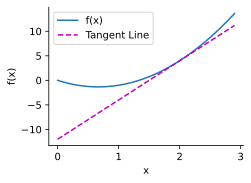

In [13]:
## 测试绘图函数
x = np.arange(0, 3, 0.1)
plot(x, [f(x), 8 * x - 12], 'x', 'f(x)', legend=['f(x)', 'Tangent Line'])

### 2.4.2 偏导
- 对于一个多元函数 $ y=f(x_1, x_2, …, x_n) $，其偏导可表示为：
$$
\frac{dy}{dx_i} = \lim_{h \to 0}\frac{f(x_1, ..., x_{i-1}, x_i+h, x_{i+1}, ..., x_n) - f(x_1, ..., x_i, ..., x_n)}{h}
$$
